In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df1 = pd.read_csv("/content/drive/MyDrive/tkbd/olist_orders_cleaned.csv")
df2 = pd.read_excel("/content/drive/MyDrive/tkbd/olist_order_review_cleaned.xlsx")
df3 = pd.read_csv("/content/drive/MyDrive/tkbd/olist_order_payments_cleaned.csv")
df4 = pd.read_csv("/content/drive/MyDrive/tkbd/olist_order_items_cleaned.csv")
df5 = pd.read_csv("/content/drive/MyDrive/tkbd/olist_customers_cleaned.csv")

gabungan = (
    df1
    .merge(df2, on="order_id", how="left")       # review ke orders
    .merge(df3, on="order_id", how="left")       # payments ke orders
    .merge(df4, on="order_id", how="left")       # items ke orders
    .merge(df5, on="customer_id", how="left")    # customer ke orders
)

print("Jumlah baris:", len(gabungan))
print("Jumlah kolom:", gabungan.shape[1])
print(gabungan.head())


Jumlah baris: 119143
Jumlah kolom: 25
                           order_id                       customer_id  \
0  5f79b5b0931d63f1a42989eb65b9da6e  00012a2ce6f8dcda20d059ce98491703   
1  a44895d095d7e0702b6a162fa2dbeced  000161a058600d5901f007fab4c27140   
2  316a104623542e4d75189bb372bc5f8d  0001fd6190edaaf884bcaf3d49edf079   
3  5825ce2e88d5346438686b0bba99e5ee  0002414f95344307404f0ace7a26f1d5   
4  0ab7fb08086d4af9141453c91878ed7a  000379cdec625522490c315e70c7a9fb   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-11-14 16:08:26  2017-11-14 16:35:32   
1    delivered      2017-07-16 09:40:32  2017-07-16 09:55:12   
2    delivered      2017-02-28 11:06:43  2017-02-28 11:15:20   
3    delivered      2017-08-16 13:09:20  2017-08-17 03:10:27   
4    delivered      2018-04-02 13:42:17  2018-04-04 03:10:19   

  order_estimated_delivery_date  churn                         review_id  \
0                    2017-12-04      1  65645c124061b43b2edc38

#cek hasil cleaning

In [ ]:
gabungan.isnull()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_estimated_delivery_date,churn,review_id,review_score,review_creation_date,...,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119138,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
119139,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
119140,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
119141,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
gabungan.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
119138,False
119139,False
119140,False
119141,False


#korelasi

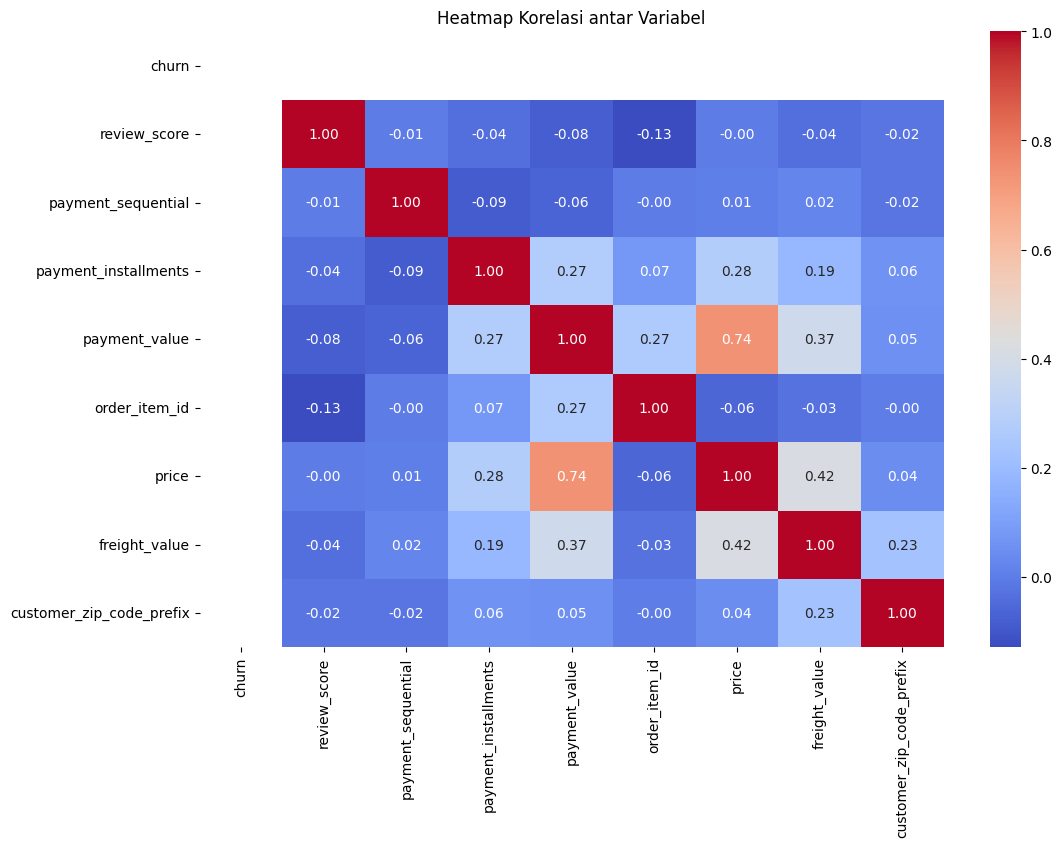

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

corr = gabungan.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Heatmap Korelasi antar Variabel")
plt.show()

#raw fitur

In [ ]:
# total nilai transaksi per customer
transaksi_total = (
    gabungan.groupby("customer_unique_id")["price"]
    .sum()
    .reset_index(name="total_transaksi")
)

transaksi_total.head()

,customer_unique_id,total_transaksi
0,0000366f3b9a7992bf8c76cfdf3221e2,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,18.90
2,0000f46a3911fa3c0805444483337064,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,25.99
4,0004aac84e0df4da2b147fca70cf8255,180.00


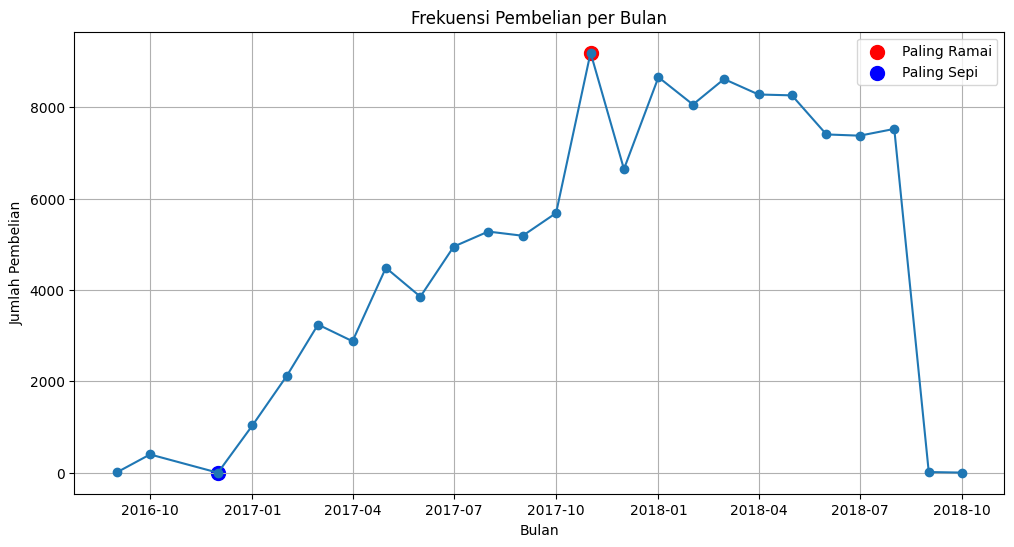

In [ ]:
import matplotlib.pyplot as plt

frekuensi_bulanan["bulan"] = frekuensi_bulanan["order_purchase_timestamp"].dt.to_timestamp()

plt.figure(figsize=(12,6))
plt.plot(frekuensi_bulanan["bulan"], frekuensi_bulanan["jumlah_pembelian"], marker="o")

plt.scatter(paling_ramai["order_purchase_timestamp"].to_timestamp(), paling_ramai["jumlah_pembelian"],
            color="red", s=100, label="Paling Ramai")
plt.scatter(paling_sepi["order_purchase_timestamp"].to_timestamp(), paling_sepi["jumlah_pembelian"],
            color="blue", s=100, label="Paling Sepi")

plt.title("Frekuensi Pembelian per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Pembelian")
plt.legend()
plt.grid(True)
plt.show()

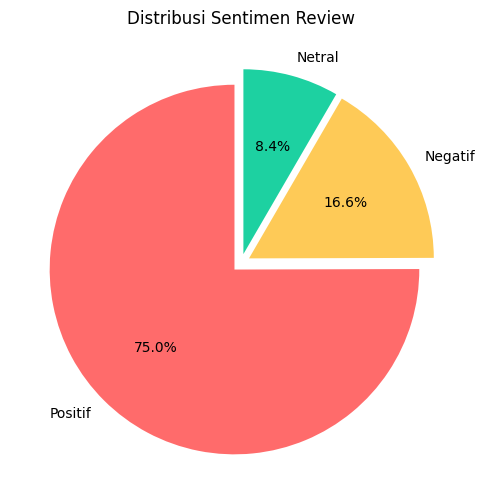

In [ ]:
import matplotlib.pyplot as plt

labels = sentimen_persen["sentimen"]
sizes = sentimen_persen["persentase"]

colors = ["#ff6b6b", "#feca57", "#1dd1a1"]  # merah, kuning, hijau

plt.figure(figsize=(6,6))
plt.pie(
    sizes,
    labels=labels,
    autopct="%.1f%%",
    startangle=90,
    colors=colors,
    explode=(0.05,0.05,0.05)
)
plt.title("Distribusi Sentimen Review")
plt.show()

In [ ]:
# cari first & last order per customer
customer_durasi = (
    gabungan.groupby("customer_unique_id")["order_purchase_timestamp"]
    .agg(["min", "max"])
    .reset_index()
)

# Convert 'min' and 'max' columns to datetime objects
customer_durasi["min"] = pd.to_datetime(customer_durasi["min"])
customer_durasi["max"] = pd.to_datetime(customer_durasi["max"])

customer_durasi["durasi_hari"] = (
    customer_durasi["max"] - customer_durasi["min"]
).dt.days

print(customer_durasi.head())

                 customer_unique_id                 min                 max  \
0  0000366f3b9a7992bf8c76cfdf3221e2 2018-05-10 10:56:27 2018-05-10 10:56:27   
1  0000b849f77a49e4a4ce2b2a4ca5be3f 2018-05-07 11:11:27 2018-05-07 11:11:27   
2  0000f46a3911fa3c0805444483337064 2017-03-10 21:05:03 2017-03-10 21:05:03   
3  0000f6ccb0745a6a4b88665a16c9f078 2017-10-12 20:29:41 2017-10-12 20:29:41   
4  0004aac84e0df4da2b147fca70cf8255 2017-11-14 19:45:42 2017-11-14 19:45:42   

   durasi_hari  
0            0  
1            0  
2            0  
3            0  
4            0  


In [ ]:
# merge fitur ke dataframe customer
fitur = transaksi_total \
    .merge(customer_durasi[["customer_unique_id", "durasi_hari"]], on="customer_unique_id", how="left")

print(fitur.head())

                 customer_unique_id  total_transaksi  durasi_hari
0  0000366f3b9a7992bf8c76cfdf3221e2           129.90            0
1  0000b849f77a49e4a4ce2b2a4ca5be3f            18.90            0
2  0000f46a3911fa3c0805444483337064            69.00            0
3  0000f6ccb0745a6a4b88665a16c9f078            25.99            0
4  0004aac84e0df4da2b147fca70cf8255           180.00            0


#analisis churn


In [ ]:
import pandas as pd

# ambil tanggal terakhir di dataset
last_date = gabungan["order_purchase_timestamp"].max()

# hitung last order per customer
last_order = (
    gabungan.groupby("customer_unique_id")["order_purchase_timestamp"]
    .max()
    .reset_index()
)

# flag churn (tidak order lagi dalam 180 hari terakhir)
last_order["churn"] = (last_date - last_order["order_purchase_timestamp"]).dt.days > 180
last_order["churn"] = last_order["churn"].astype(int)

In [ ]:
# nilai transaksi
gabungan["nilai_order"] = gabungan["price"].fillna(0) + gabungan["freight_value"].fillna(0)
transaksi_total = gabungan.groupby("customer_unique_id")["nilai_order"].sum().reset_index(name="total_transaksi")

# frekuensi (jumlah order)
frekuensi = gabungan.groupby("customer_unique_id")["order_id"].nunique().reset_index(name="jumlah_order")

# sentimen rata-rata (bisa juga persen positif/negatif per customer)
gabungan["sentimen_score"] = gabungan["review_score"].fillna(3)  # isi kosong dengan netral
sentimen = gabungan.groupby("customer_unique_id")["sentimen_score"].mean().reset_index(name="rata_sentimen")

# durasi (hari aktif)
durasi = (
    gabungan.groupby("customer_unique_id")["order_purchase_timestamp"]
    .agg(["min", "max"])
    .reset_index()
)
durasi["durasi_hari"] = (durasi["max"] - durasi["min"]).dt.days
durasi = durasi[["customer_unique_id", "durasi_hari"]]

In [ ]:
fitur = (
    transaksi_total
    .merge(frekuensi, on="customer_unique_id", how="left")
    .merge(sentimen, on="customer_unique_id", how="left")
    .merge(durasi, on="customer_unique_id", how="left")
    .merge(last_order[["customer_unique_id", "churn"]], on="customer_unique_id", how="left")
)

print(fitur.head())

                 customer_unique_id  total_transaksi  jumlah_order  \
0  0000366f3b9a7992bf8c76cfdf3221e2           141.90             1   
1  0000b849f77a49e4a4ce2b2a4ca5be3f            27.19             1   
2  0000f46a3911fa3c0805444483337064            86.22             1   
3  0000f6ccb0745a6a4b88665a16c9f078            43.62             1   
4  0004aac84e0df4da2b147fca70cf8255           196.89             1   

   rata_sentimen  durasi_hari  churn  
0            5.0            0      0  
1            4.0            0      0  
2            3.0            0      1  
3            4.0            0      1  
4            5.0            0      1  


In [ ]:
print(fitur.drop("customer_unique_id", axis=1).groupby("churn").mean())

       total_transaksi  jumlah_order  rata_sentimen  durasi_hari
churn                                                           
0           176.608419      1.040420       4.233001     4.951145
1           171.798446      1.032504       4.012128     1.791485


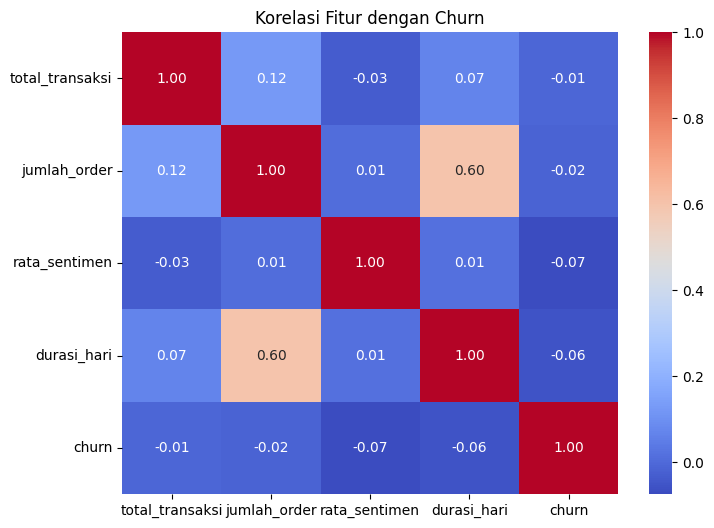

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = fitur.drop(columns=["customer_unique_id"]).corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasi Fitur dengan Churn")
plt.show()

#pelatihan model

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# ambil fitur & target
X = fitur[["total_transaksi", "jumlah_order", "rata_sentimen", "durasi_hari"]]
y = fitur["churn"]

# split data: 30% train, 70% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.7, random_state=42, stratify=y
)

# buat model Logistic Regression dengan balancing
logreg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)

# training
logreg.fit(X_train, y_train)

# prediksi di data testing
y_pred = logreg.predict(X_test)

# laporan evaluasi
print("=== Classification Report ===")
print(classification_report(y_test, y_pred, digits=3))

# confusion matrix
print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))


=== Classification Report ===
              precision    recall  f1-score   support

           0      0.317     0.641     0.425     19587
           1      0.746     0.433     0.548     47681

    accuracy                          0.494     67268
   macro avg      0.532     0.537     0.486     67268
weighted avg      0.621     0.494     0.512     67268

=== Confusion Matrix ===
[[12560  7027]
 [27027 20654]]


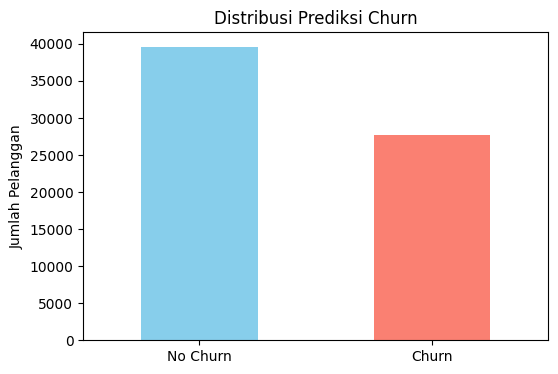

In [ ]:
import matplotlib.pyplot as plt

# prediksi
y_pred = logreg.predict(X_test)

# hitung jumlah prediksi churn dan tidak churn
churn_counts = pd.Series(y_pred).value_counts()

# bar chart
plt.figure(figsize=(6,4))
churn_counts.plot(kind="bar", color=["skyblue", "salmon"])
plt.xticks([0,1], ["No Churn", "Churn"], rotation=0)
plt.ylabel("Jumlah Pelanggan")
plt.title("Distribusi Prediksi Churn")
plt.show()

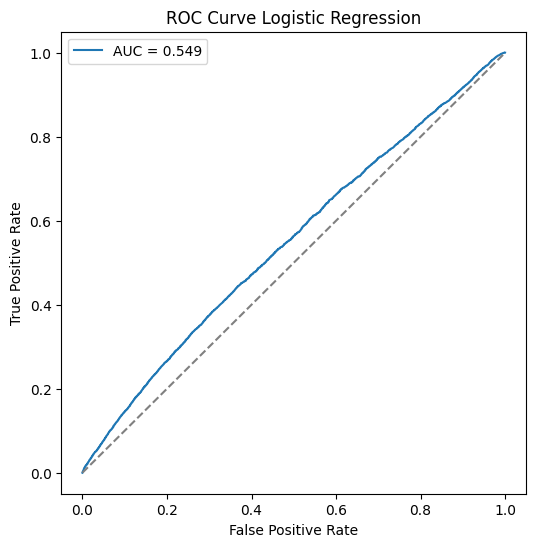

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# probabilitas churn
y_prob = logreg.predict_proba(X_test)[:,1]

# hitung ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0,1],[0,1],"--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Logistic Regression")
plt.legend()
plt.show()

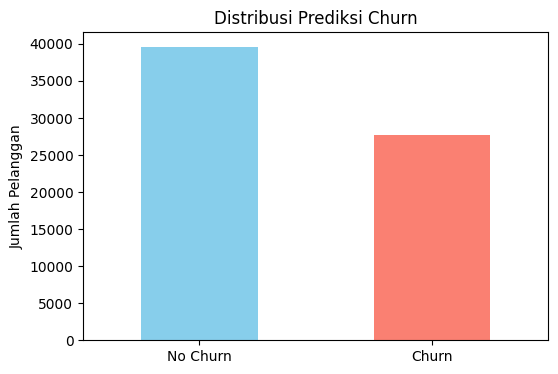

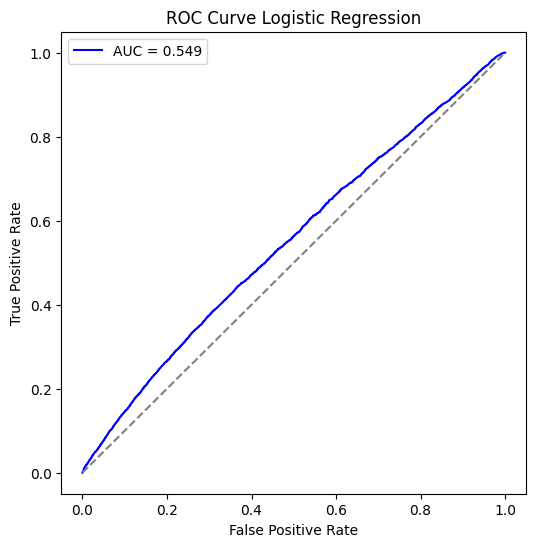

=== Top 10 Pelanggan dengan Risiko Churn Tertinggi ===
       total_transaksi  jumlah_order  rata_sentimen  durasi_hari  actual  \
52973           902.04            17       4.764706          461       0   
23472          1172.67             9       2.642857          161       1   
7175            110.72             6       5.000000            0       1   
83540           530.38             6       3.000000           75       1   
10354          1021.12             7       5.000000           92       1   
68007           382.42             5       4.142857           35       1   
38635           296.60             3       1.000000            0       1   
14199           131.80             4       4.000000            1       1   
61616           457.19             3       1.750000            0       1   
49622            73.48             4       5.000000            0       1   

       predicted  churn_probability  
52973          1           0.941386  
23472          1           0.878

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import roc_curve, roc_auc_score, classification_report

# 1. Prediksi churn
y_pred = logreg.predict(X_test)
y_prob = logreg.predict_proba(X_test)[:, 1]  # probabilitas churn

# 2. Simpan hasil prediksi & probabilitas ke dataframe
hasil_prediksi = X_test.copy()
hasil_prediksi["actual"] = y_test.values
hasil_prediksi["predicted"] = y_pred
hasil_prediksi["churn_probability"] = y_prob

# 3. Grafik distribusi prediksi churn vs tidak churn
plt.figure(figsize=(6,4))
pd.Series(y_pred).value_counts().sort_index().plot(
    kind="bar", color=["skyblue", "salmon"]
)
plt.xticks([0,1], ["No Churn", "Churn"], rotation=0)
plt.ylabel("Jumlah Pelanggan")
plt.title("Distribusi Prediksi Churn")
plt.show()

# 4. ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}", color="blue")
plt.plot([0,1],[0,1],"--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Logistic Regression")
plt.legend()
plt.show()

# 5. Top pelanggan dengan probabilitas churn tertinggi
top_churn = hasil_prediksi.sort_values("churn_probability", ascending=False).head(10)
print("=== Top 10 Pelanggan dengan Risiko Churn Tertinggi ===")
print(top_churn)

#random forest

=== Classification Report ===
              precision    recall  f1-score   support

           0      0.453     0.461     0.457     19587
           1      0.777     0.772     0.774     47681

    accuracy                          0.681     67268
   macro avg      0.615     0.616     0.616     67268
weighted avg      0.683     0.681     0.682     67268

=== Confusion Matrix ===
[[ 9021 10566]
 [10889 36792]]


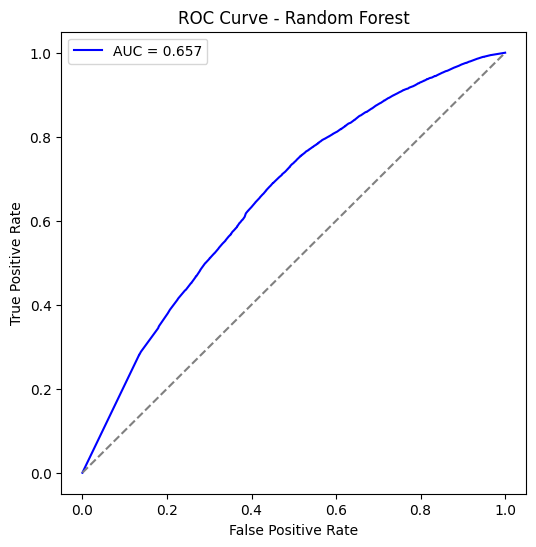

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt

# ambil fitur & target
X = fitur[["total_transaksi", "jumlah_order", "rata_sentimen", "durasi_hari"]]
y = fitur["churn"]

# split data: 30% train, 70% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.7, random_state=42, stratify=y
)

# buat model Random Forest
rf = RandomForestClassifier(
    n_estimators=100,      # jumlah pohon
    random_state=42,
    class_weight="balanced"  # biar ngimbangin churn dan no-churn
)

# training
rf.fit(X_train, y_train)

# prediksi
y_pred = rf.predict(X_test)
y_pred_proba = rf.predict_proba(X_test)[:, 1]

# evaluasi
print("=== Classification Report ===")
print(classification_report(y_test, y_pred, digits=3))

print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color="blue", label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.show()

In [ ]:
import pandas as pd

# prediksi churn pakai Random Forest
y_pred = rf.predict(X_test)
y_pred_proba = rf.predict_proba(X_test)[:, 1]

# gabungin hasil prediksi ke dataframe
hasil_prediksi = X_test.copy()
hasil_prediksi["actual"] = y_test
hasil_prediksi["predicted"] = y_pred
hasil_prediksi["churn_probability"] = y_pred_proba

# sort pelanggan berdasarkan risiko churn (prob tertinggi)
top_churn = hasil_prediksi.sort_values(by="churn_probability", ascending=False).head(10)

print("=== Top 10 Pelanggan dengan Risiko Churn Tertinggi (Random Forest) ===")
print(top_churn)

=== Top 10 Pelanggan dengan Risiko Churn Tertinggi (Random Forest) ===
       total_transaksi  jumlah_order  rata_sentimen  durasi_hari  actual  \
37824           196.01             1            5.0            0       1   
393             273.25             1            5.0            0       1   
76525           120.09             1            5.0            0       1   
72927           234.60             1            1.0            0       0   
51903           174.73             1            5.0            0       0   
3498             89.36             1            1.0            0       0   
83859           101.78             1            5.0            0       0   
79615           140.33             1            5.0            0       1   
11300           127.09             1            1.0            0       1   
8583            366.90             1            5.0            0       1   

       predicted  churn_probability  
37824          1                1.0  
393            1